# Prompt sensitivity of zero-shot CLIP on GTSRB
Runtime → Change runtime type → **T4 GPU**, then Run all. Takes about 10 minutes.

In [1]:
%%writefile prompt_sensitivity.py
"""
Prompt sensitivity of zero-shot CLIP (ViT-B/32) on a fine-grained GTSRB subset.

Claim tested: changing only the prompt template (model, data, classes fixed)
moves top-1 accuracy by a double-digit percentage-point spread.

Usage (Colab, GPU runtime):
    python prompt_sensitivity.py --data-root data --out results

Step 1 (needs torch + network): encode every test image once -> cached .npz
Step 2 (numpy only): for each template, encode the 18 class prompts, classify,
        and compute accuracy, bootstrap CIs, McNemar tests vs. the baseline
        template, per-class sensitivity, confusion matrices and figures.
"""
import argparse
import json
import os
import random

import numpy as np

# --------------------------------------------------------------------------
# Experimental setup (fixed before running; do not tune on results)
# --------------------------------------------------------------------------

# GTSRB class id -> class description substituted into {class}.
# Names deliberately omit the word "sign" so template 5 ("... {class} sign on a
# road") stays grammatical; this is applied identically to every template.
CLASSES = {
    0: "speed limit 20 km/h",
    1: "speed limit 30 km/h",
    2: "speed limit 50 km/h",
    3: "speed limit 60 km/h",
    4: "speed limit 70 km/h",
    5: "speed limit 80 km/h",
    7: "speed limit 100 km/h",
    8: "speed limit 120 km/h",
    18: "general caution",
    19: "dangerous curve to the left",
    20: "dangerous curve to the right",
    21: "double curve",
    22: "bumpy road",
    23: "slippery road",
    24: "road narrows on the right",
    25: "road work",
    26: "traffic signals",
    27: "pedestrians",
}

TEMPLATES = {
    "T1 bare": "{c}",
    "T2 photo (baseline)": "a photo of a {c}",
    "T3 domain": "a photo of a {c}, a type of traffic sign",
    "T4 functional": "a road sign indicating {c}",
    "T5 blurry/context": "a blurry photo of a {c} sign on a road",
    "T6 verbose": "a photograph of a {c}, showing its visual characteristics and function as a traffic sign",
    "T7 irrelevant": "a photo of a {c}, taken on a sunny day",
}
BASELINE = "T2 photo (baseline)"
MODEL_NAME = "openai/clip-vit-base-patch32"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


# --------------------------------------------------------------------------
# Step 1: encoding (torch / transformers)
# --------------------------------------------------------------------------

def load_model(device):
    from transformers import CLIPModel, CLIPProcessor
    model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
    proc = CLIPProcessor.from_pretrained(MODEL_NAME)
    return model, proc


# Computed explicitly (encoder pooled output -> projection) rather than via
# get_image_features/get_text_features, whose return type changed across
# transformers versions (tensor in 4.x, ModelOutput in 5.x).
def image_embed(model, inputs):
    pooled = model.vision_model(pixel_values=inputs["pixel_values"]).pooler_output
    return model.visual_projection(pooled)


def text_embed(model, inputs):
    pooled = model.text_model(input_ids=inputs["input_ids"],
                              attention_mask=inputs["attention_mask"]).pooler_output
    return model.text_projection(pooled)


# Official GTSRB test-split image counts for some classes, used to confirm a
# mirror's labels use the original class ids.
EXPECTED_TEST_COUNTS = {0: 60, 1: 720, 2: 750, 19: 60, 25: 480, 27: 60}


def _check_counts(samples, source):
    counts = {}
    for _, t in samples:
        counts[t] = counts.get(t, 0) + 1
    bad = {k: (counts.get(k, 0), v) for k, v in EXPECTED_TEST_COUNTS.items() if counts.get(k, 0) != v}
    total = sum(counts.values())
    if bad or total != 12630:
        raise ValueError(f"{source}: test split doesn't match official GTSRB "
                         f"(total {total}, expected 12630; mismatches {bad})")
    print(f"Data source: {source} — {total} test images, label check passed")


def load_gtsrb_test(data_root):
    """Return (samples, loader, source): samples = [(key, class_id)], loader(key) -> PIL RGB.
    The official host (sid.erda.dk) often times out from Colab, so mirrors come first."""
    from PIL import Image
    errors = []

    # 1) Kaggle mirror of the official files; labels from the official Test.csv
    try:
        import csv
        import kagglehub
        root = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
        csv_path = next(os.path.join(d, "Test.csv") for d, _, fs in os.walk(root) if "Test.csv" in fs)
        base = os.path.dirname(csv_path)
        with open(csv_path) as f:
            samples = [(os.path.join(base, r["Path"]), int(r["ClassId"])) for r in csv.DictReader(f)]
        _check_counts(samples, "Kaggle mirror")
        return samples, lambda p: Image.open(p).convert("RGB"), "Kaggle mirror (meowmeowmeowmeowmeow/gtsrb-german-traffic-sign)"
    except Exception as e:
        errors.append(f"Kaggle: {e!r}")
        print("Kaggle mirror failed, trying Hugging Face:", repr(e)[:200])

    # 2) Hugging Face mirror
    try:
        from datasets import load_dataset
        ds = load_dataset("tanganke/gtsrb", split="test", cache_dir=os.path.join(data_root, "hf"))
        samples = list(enumerate(ds["label"]))
        _check_counts(samples, "Hugging Face mirror")
        return samples, lambda i: ds[i]["image"].convert("RGB"), "Hugging Face mirror (tanganke/gtsrb)"
    except Exception as e:
        errors.append(f"Hugging Face: {e!r}")
        print("Hugging Face mirror failed, trying the official host:", repr(e)[:200])

    # 3) Official host via torchvision
    try:
        from torchvision.datasets import GTSRB
        ds = GTSRB(root=data_root, split="test", download=True)
        samples = list(ds._samples)
        _check_counts(samples, "official (torchvision)")
        return samples, lambda p: Image.open(p).convert("RGB"), "official host via torchvision"
    except Exception as e:
        errors.append(f"torchvision: {e!r}")

    raise RuntimeError("Could not get GTSRB from any source:\n" + "\n".join(errors))


def encode_images(data_root, cache_path, device, batch_size, max_per_class, seed):
    import torch

    all_samples, loader, source = load_gtsrb_test(data_root)
    with open(os.path.join(os.path.dirname(cache_path), "data_source.txt"), "w") as f:
        f.write(source + "\n")
    samples = [(p, t) for p, t in all_samples if t in CLASSES]
    if max_per_class:
        rng = random.Random(seed)
        by_cls = {}
        for p, t in samples:
            by_cls.setdefault(t, []).append((p, t))
        samples = []
        for t in sorted(by_cls):
            items = by_cls[t]
            rng.shuffle(items)
            samples += items[:max_per_class]
    print(f"{len(samples)} test images across {len(CLASSES)} classes")

    model, proc = load_model(device)
    feats, labels = [], []
    with torch.no_grad():
        for i in range(0, len(samples), batch_size):
            batch = samples[i:i + batch_size]
            imgs = [loader(p) for p, _ in batch]
            inputs = proc(images=imgs, return_tensors="pt").to(device)
            f = image_embed(model, inputs)
            f = f / f.norm(dim=-1, keepdim=True)
            feats.append(f.cpu().numpy())
            labels += [t for _, t in batch]
            if (i // batch_size) % 20 == 0:
                print(f"  encoded {i + len(batch)}/{len(samples)}")
    feats = np.concatenate(feats).astype(np.float32)
    labels = np.array(labels)
    np.savez(cache_path, feats=feats, labels=labels,
             class_ids=np.array(sorted(CLASSES)), model=MODEL_NAME)
    return feats, labels


def encode_texts(device):
    """Return {template_name: (n_classes, d) normalised text embeddings}."""
    import torch
    model, proc = load_model(device)
    out = {}
    with torch.no_grad():
        for name, tpl in TEMPLATES.items():
            prompts = [tpl.format(c=CLASSES[k]) for k in sorted(CLASSES)]
            inputs = proc(text=prompts, return_tensors="pt", padding=True).to(device)
            t = text_embed(model, inputs)
            t = t / t.norm(dim=-1, keepdim=True)
            out[name] = t.cpu().numpy().astype(np.float32)
        logit_scale = float(model.logit_scale.exp().item())  # 100 for ViT-B/32
    return out, logit_scale


# --------------------------------------------------------------------------
# Step 2: analysis (numpy only, so it can be re-run without a GPU)
# --------------------------------------------------------------------------

def bootstrap_ci(correct, n_boot, rng):
    n = len(correct)
    idx = rng.integers(0, n, size=(n_boot, n))
    accs = correct[idx].mean(axis=1)
    return float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))


def mcnemar_p(a_correct, b_correct):
    """Exact McNemar test on paired per-image correctness."""
    from scipy.stats import binomtest
    b = int(np.sum(a_correct & ~b_correct))
    c = int(np.sum(~a_correct & b_correct))
    if b + c == 0:
        return 1.0
    return float(binomtest(b, b + c, 0.5).pvalue)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def expected_calibration_error(conf, correct, n_bins=15):
    """ECE: average |accuracy - confidence| over equal-width confidence bins,
    weighted by the fraction of images in each bin."""
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def analyse(feats, labels, text_embs, out_dir, seed=0, n_boot=1000, logit_scale=100.0):
    import pandas as pd
    os.makedirs(out_dir, exist_ok=True)
    rng = np.random.default_rng(seed)
    class_ids = sorted(CLASSES)
    y = np.searchsorted(class_ids, labels)  # GTSRB id -> 0..K-1
    K = len(class_ids)

    # Prompt ensemble (mean of the 7 templates) as an extra, clearly-labelled row
    ens = np.mean([text_embs[n] for n in TEMPLATES], axis=0)
    ens /= np.linalg.norm(ens, axis=1, keepdims=True)
    all_embs = dict(text_embs)
    all_embs["Ensemble of T1-T7"] = ens

    # CLIP's own class probabilities: softmax(logit_scale * cosine similarity).
    # "confidence" = probability of the class CLIP picked.
    preds, correct, conf = {}, {}, {}
    for name, T in all_embs.items():
        probs = softmax(logit_scale * (feats @ T.T))
        preds[name] = probs.argmax(axis=1)
        conf[name] = probs.max(axis=1)
        correct[name] = preds[name] == y

    counts = np.bincount(y, minlength=K)
    majority_acc = counts.max() / counts.sum()
    chance_acc = 1.0 / K

    rows = []
    for name in all_embs:
        cor = correct[name]
        per_cls = np.array([cor[y == k].mean() for k in range(K)])
        lo, hi = bootstrap_ci(cor, n_boot, rng)
        rows.append({
            "template": name,
            "prompt_example": (TEMPLATES[name].format(c=CLASSES[1]) if name in TEMPLATES else "mean of T1-T7 embeddings"),
            "top1": cor.mean(),
            "top1_ci_lo": lo,
            "top1_ci_hi": hi,
            "balanced_acc": per_cls.mean(),
            "delta_vs_baseline_pp": 100 * (cor.mean() - correct[BASELINE].mean()),
            "mcnemar_p_vs_baseline": (np.nan if name == BASELINE else mcnemar_p(cor, correct[BASELINE])),
            "mean_confidence": float(conf[name].mean()),
            "overconfidence_pp": float(100 * (conf[name].mean() - cor.mean())),
            "ece": expected_calibration_error(conf[name], cor),
            "mean_conf_when_wrong": float(conf[name][~cor].mean()) if (~cor).any() else np.nan,
        })
    summary = pd.DataFrame(rows)
    summary.to_csv(os.path.join(out_dir, "template_accuracy.csv"), index=False)

    t_only = summary[summary.template.isin(TEMPLATES)]
    spread = {
        "n_images": int(len(y)),
        "n_classes": K,
        "chance_acc": chance_acc,
        "majority_class_acc": float(majority_acc),
        "top1_mean": float(t_only.top1.mean()),
        "top1_std": float(t_only.top1.std(ddof=1)),
        "top1_min": float(t_only.top1.min()),
        "top1_max": float(t_only.top1.max()),
        "top1_range_pp": float(100 * (t_only.top1.max() - t_only.top1.min())),
        "best_template": t_only.loc[t_only.top1.idxmax(), "template"],
        "worst_template": t_only.loc[t_only.top1.idxmin(), "template"],
        "balanced_range_pp": float(100 * (t_only.balanced_acc.max() - t_only.balanced_acc.min())),
        # Calibration: would picking the most *confident* template (no labels
        # needed) have picked the most *accurate* one?
        "most_confident_template": t_only.loc[t_only.mean_confidence.idxmax(), "template"],
        "most_confident_template_top1": float(t_only.loc[t_only.mean_confidence.idxmax(), "top1"]),
        "confidence_picks_best": bool(t_only.mean_confidence.idxmax() == t_only.top1.idxmax()),
        "spearman_conf_vs_acc_across_templates": float(
            t_only.mean_confidence.rank().corr(t_only.top1.rank())),
        "logit_scale": logit_scale,
    }
    # Bootstrap CI on the range itself (same resample applied to all templates)
    n = len(y)
    C = np.stack([correct[t] for t in TEMPLATES])  # (7, n)
    ranges = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        a = C[:, idx].mean(axis=1)
        ranges.append(a.max() - a.min())
    spread["top1_range_pp_ci"] = [float(100 * np.percentile(ranges, 2.5)),
                                  float(100 * np.percentile(ranges, 97.5))]
    with open(os.path.join(out_dir, "spread_summary.json"), "w") as f:
        json.dump(spread, f, indent=2)

    # Per-class x template accuracy; sensitivity = range across templates
    pc = pd.DataFrame(
        {name: [correct[name][y == k].mean() for k in range(K)] for name in TEMPLATES},
        index=[CLASSES[k] for k in class_ids],
    )
    pc["n_images"] = counts
    pc["range_pp"] = 100 * (pc[list(TEMPLATES)].max(axis=1) - pc[list(TEMPLATES)].min(axis=1))
    pc["std_pp"] = 100 * pc[list(TEMPLATES)].std(axis=1, ddof=1)
    pc = pc.sort_values("range_pp", ascending=False)
    pc.to_csv(os.path.join(out_dir, "per_class_accuracy.csv"))

    # Confusion matrices for best & worst template
    for tag in ("best_template", "worst_template"):
        name = spread[tag]
        cm = np.zeros((K, K), dtype=int)
        np.add.at(cm, (y, preds[name]), 1)
        pd.DataFrame(cm, index=[CLASSES[k] for k in class_ids],
                     columns=[CLASSES[k] for k in class_ids]).to_csv(
            os.path.join(out_dir, f"confusion_{tag}.csv"))

    make_figures(summary, pc, spread, preds, y, class_ids, out_dir)
    make_calibration_figure(summary, conf, correct, out_dir)
    return summary, pc, spread


def make_calibration_figure(summary, conf, correct, out_dir, n_bins=10):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    t_only = summary[summary.template.isin(TEMPLATES)]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # (a) one point per template: mean confidence vs actual accuracy
    ax = axes[0]
    ax.plot([0, 100], [0, 100], ls="--", c="grey", lw=1, label="perfectly calibrated")
    # Labels go in a stacked column to the right of the cluster, with leader
    # lines, so they never overlap even when the points sit almost on top of each other.
    pts = sorted(((100 * r.top1, 100 * r.mean_confidence, r.template) for _, r in t_only.iterrows()),
                 reverse=True)
    n_pts = len(pts)
    for i, (yv, xv, tname) in enumerate(pts):
        c = "#d62728" if tname == BASELINE else "#1f77b4"
        ax.scatter(xv, yv, c=c, s=40, zorder=3)
        ax.annotate(tname.split(" ")[0], (xv, yv), textcoords="offset points",
                    xytext=(45, 6 * (n_pts - 1) - 12 * i), fontsize=8, va="center",
                    arrowprops=dict(arrowstyle="-", lw=0.5, color="grey"))
    lo = 100 * min(t_only.mean_confidence.min(), t_only.top1.min()) - 5
    ax.set_xlim(max(0, lo), 100)
    ax.set_ylim(max(0, lo), 100)
    ax.set_xlabel("Mean confidence of CLIP's chosen class (%)")
    ax.set_ylabel("Actual top-1 accuracy (%)")
    ax.set_title("Above the line = underconfident, below = overconfident", fontsize=9)
    ax.legend(fontsize=8, loc="upper left")

    # (b) reliability diagram for the most and least accurate templates
    ax = axes[1]
    edges = np.linspace(0, 1, n_bins + 1)
    mids = (edges[:-1] + edges[1:]) / 2
    best = t_only.loc[t_only.top1.idxmax(), "template"]
    worst = t_only.loc[t_only.top1.idxmin(), "template"]
    ax.plot([0, 100], [0, 100], ls="--", c="grey", lw=1)
    for name, col in ((best, "#2ca02c"), (worst, "#ff7f0e")):
        accs = []
        for lo_e, hi_e in zip(edges[:-1], edges[1:]):
            m = (conf[name] > lo_e) & (conf[name] <= hi_e)
            accs.append(100 * correct[name][m].mean() if m.sum() >= 10 else np.nan)
        ax.plot(100 * mids, accs, marker="o", c=col, label=f"{name} (most accurate)" if name == best
                else f"{name} (least accurate)")
    ax.set_xlabel("Confidence bin (%)")
    ax.set_ylabel("Accuracy within bin (%)")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_title("Reliability diagram (bins with ≥10 images)", fontsize=9)
    ax.legend(fontsize=8, loc="upper left")

    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "fig4_confidence_vs_accuracy.png"), dpi=200)
    plt.close(fig)


def make_figures(summary, pc, spread, preds, y, class_ids, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    # Fig 1: top-1 per template with 95% bootstrap CI, chance and majority lines
    fig, ax = plt.subplots(figsize=(8, 4.2))
    s = summary.reset_index(drop=True)
    colors = ["#888888" if t.startswith("Ensemble") else
              ("#d62728" if t == BASELINE else "#1f77b4") for t in s.template]
    x = np.arange(len(s))
    acc = 100 * s.top1
    err = [acc - 100 * s.top1_ci_lo, 100 * s.top1_ci_hi - acc]
    ax.bar(x, acc, yerr=err, capsize=4, color=colors)
    ax.axhline(100 * spread["chance_acc"], ls=":", c="k", lw=1, label=f"chance (1/{spread['n_classes']})")
    ax.axhline(100 * spread["majority_class_acc"], ls="--", c="k", lw=1, label="majority class")
    ax.set_xticks(x)
    ax.set_xticklabels(s.template, rotation=30, ha="right", fontsize=8)
    ax.set_xlabel("Prompt template")
    ax.set_ylabel("Top-1 accuracy (%)")
    ax.set_title(f"Zero-shot CLIP ViT-B/32 on {spread['n_classes']} GTSRB classes — range across T1–T7: "
                 f"{spread['top1_range_pp']:.1f} pp", fontsize=9)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "fig1_template_accuracy.png"), dpi=200)
    plt.close(fig)

    # Fig 2: per-class x template heatmap, rows sorted by sensitivity
    tcols = list(TEMPLATES)
    M = 100 * pc[tcols].values
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=100)
    ax.set_xticks(range(len(tcols)))
    ax.set_xticklabels([t.split(" ")[0] for t in tcols])
    ax.set_yticks(range(len(pc)))
    ax.set_yticklabels([f"{c} (range {r:.0f} pp)" for c, r in zip(pc.index, pc.range_pp)], fontsize=7)
    ax.set_xlabel("Prompt template")
    ax.set_title("Per-class accuracy (%), classes sorted by sensitivity to template", fontsize=9)
    fig.colorbar(im, ax=ax, label="Accuracy (%)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "fig2_per_class_heatmap.png"), dpi=200)
    plt.close(fig)

    # Fig 3: confusion matrices (row-normalised) for best and worst template
    K = len(class_ids)
    names = [CLASSES[k] for k in class_ids]
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for ax, tag in zip(axes, ("best_template", "worst_template")):
        name = spread[tag]
        cm = np.zeros((K, K))
        np.add.at(cm, (y, preds[name]), 1)
        cm = 100 * cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks(range(K))
        ax.set_xticklabels(names, rotation=90, fontsize=6)
        ax.set_yticks(range(K))
        ax.set_yticklabels(names, fontsize=6)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.set_title(f"{tag.split('_')[0].title()}: {name} (% of true class)", fontsize=9)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "fig3_confusion_best_worst.png"), dpi=200)
    plt.close(fig)


# --------------------------------------------------------------------------

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--out", default="results")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--batch-size", type=int, default=256)
    ap.add_argument("--max-per-class", type=int, default=0,
                    help="0 = use all test images of the 18 classes")
    ap.add_argument("--n-boot", type=int, default=1000)
    args = ap.parse_args()

    set_seed(args.seed)
    os.makedirs(args.out, exist_ok=True)
    import torch
    device = "cuda" if torch.cuda.is_available() else "cpu"
    cache = os.path.join(args.out, "image_features.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        if "class_ids" not in d.files or list(d["class_ids"]) != sorted(CLASSES) \
                or str(d["model"]) != MODEL_NAME:
            raise RuntimeError(f"Stale cache {cache} (made with different classes/model, or "
                               "by an older version of this script). Delete it or use a fresh --out.")
        feats, labels = d["feats"], d["labels"]
        print(f"Loaded cached features: {feats.shape}")
    else:
        feats, labels = encode_images(args.data_root, cache, device,
                                      args.batch_size, args.max_per_class, args.seed)
    text_embs, logit_scale = encode_texts(device)
    np.savez(os.path.join(args.out, "text_features.npz"), **text_embs)

    summary, pc, spread = analyse(feats, labels, text_embs, args.out, args.seed,
                                  args.n_boot, logit_scale)
    print("\n=== Top-1 per template ===")
    print(summary[["template", "top1", "top1_ci_lo", "top1_ci_hi", "balanced_acc",
                   "delta_vs_baseline_pp", "mcnemar_p_vs_baseline"]].round(4).to_string(index=False))
    print("\n=== Confidence vs accuracy per template ===")
    print(summary[["template", "top1", "mean_confidence", "overconfidence_pp", "ece",
                   "mean_conf_when_wrong"]].round(4).to_string(index=False))
    print("\n=== Spread across T1-T7 ===")
    print(json.dumps(spread, indent=2))
    print("\n=== Most template-sensitive classes ===")
    print(pc[["range_pp", "std_pp", "n_images"]].head(8).round(1).to_string())


if __name__ == "__main__":
    main()


Writing prompt_sensitivity.py


In [2]:
!pip -q install kagglehub datasets
!nvidia-smi -L
# %run (not !python) so any error stops Run all and shows the real traceback
%run prompt_sensitivity.py --data-root data --out results

GPU 0: Tesla T4 (UUID: GPU-2d9d142b-e85f-b06e-306b-0fe392d38399)
Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Data source: Kaggle mirror — 12630 test images, label check passed
5880 test images across 18 classes


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

  encoded 256/5880
  encoded 5376/5880


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


=== Top-1 per template ===
           template   top1  top1_ci_lo  top1_ci_hi  balanced_acc  delta_vs_baseline_pp  mcnemar_p_vs_baseline
            T1 bare 0.5350      0.5226      0.5475        0.4101                3.4694                 0.0000
T2 photo (baseline) 0.5003      0.4871      0.5126        0.3659                0.0000                    NaN
          T3 domain 0.4463      0.4345      0.4592        0.3496               -5.4082                 0.0000
      T4 functional 0.4500      0.4374      0.4629        0.3614               -5.0340                 0.0000
  T5 blurry/context 0.4260      0.4131      0.4388        0.3211               -7.4320                 0.0000
         T6 verbose 0.4291      0.4160      0.4406        0.3185               -7.1259                 0.0000
      T7 irrelevant 0.4662      0.4536      0.4787        0.3112               -3.4184                 0.0000
  Ensemble of T1-T7 0.4828      0.4704      0.4961        0.3575               -1.7517      

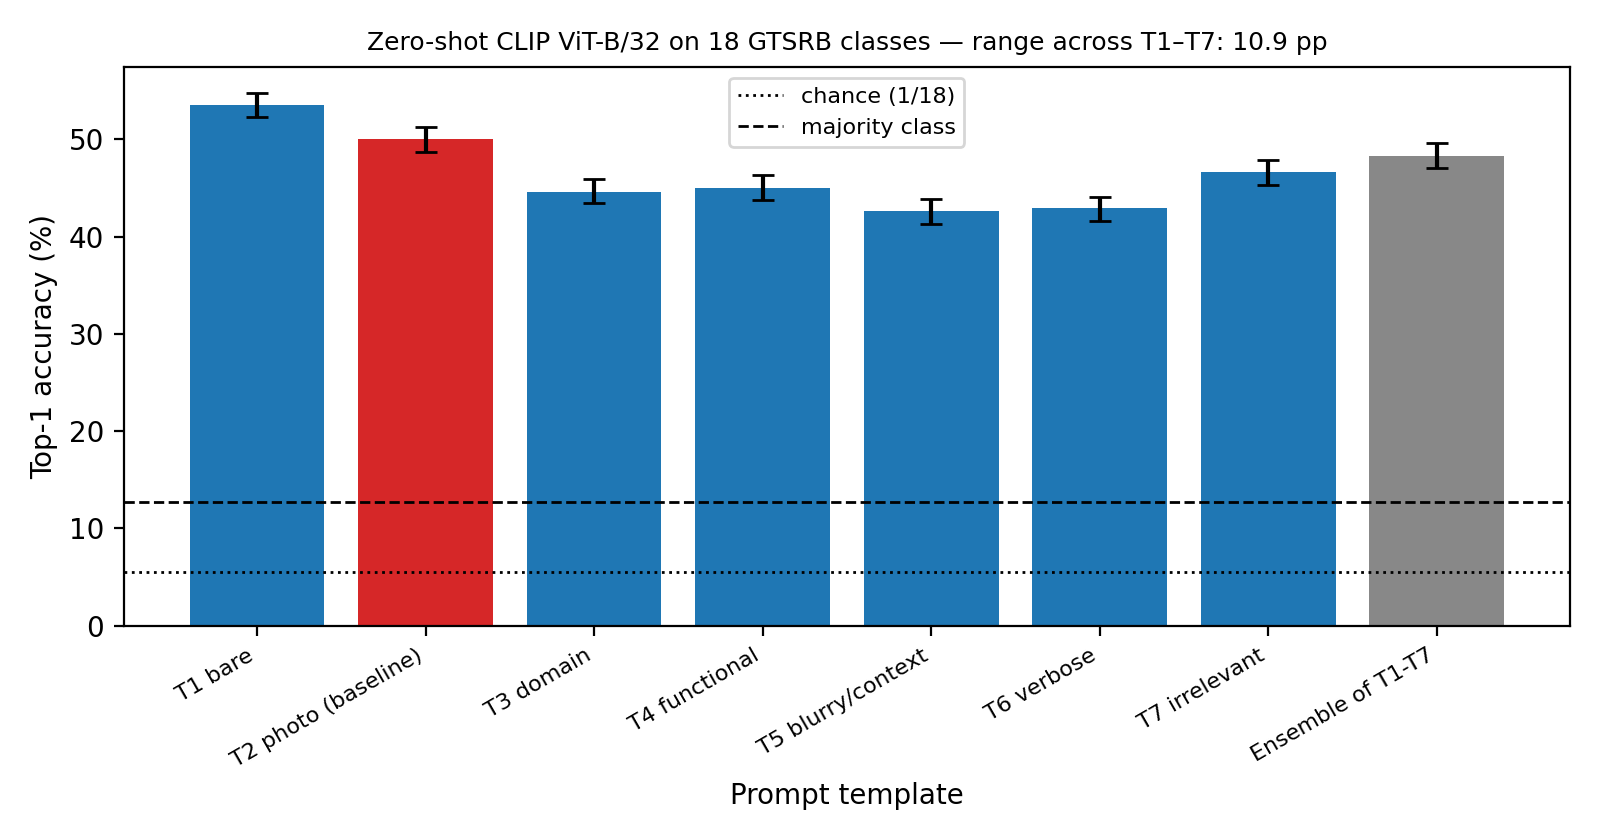

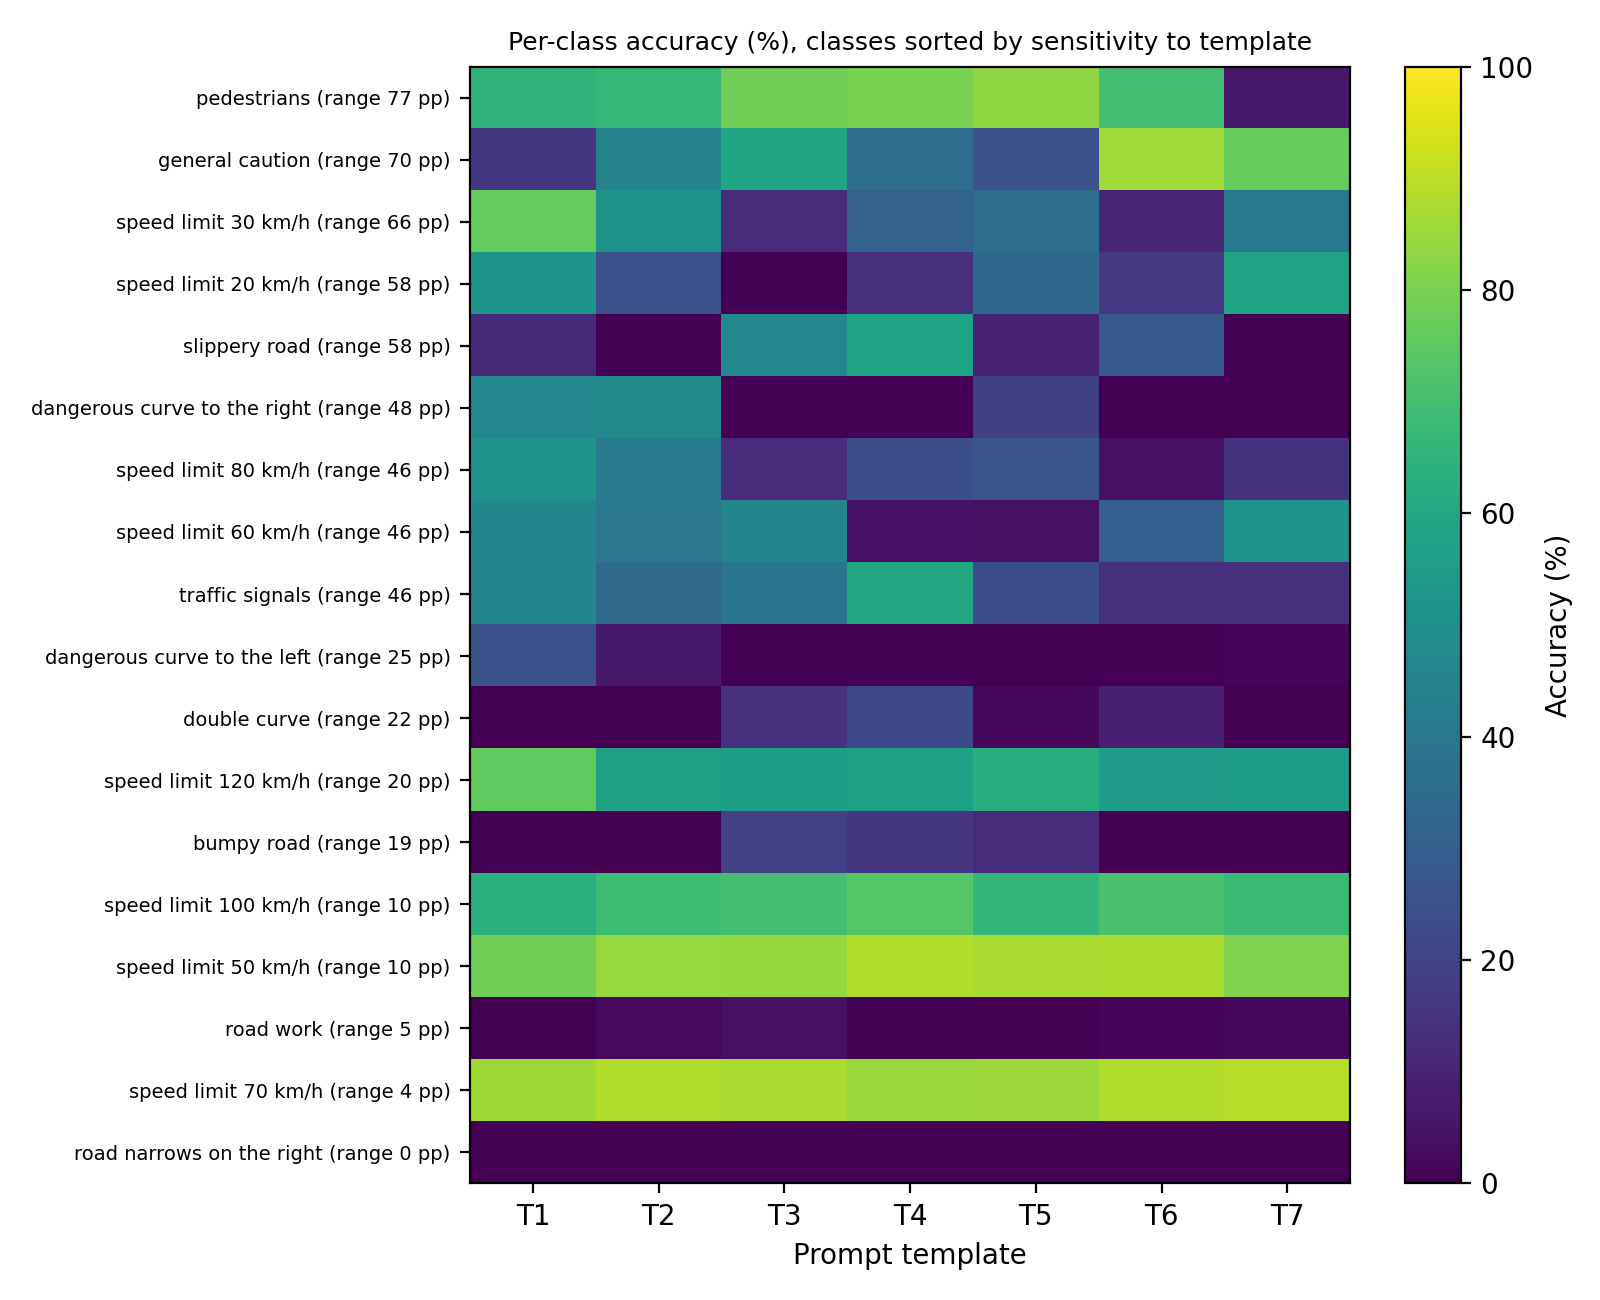

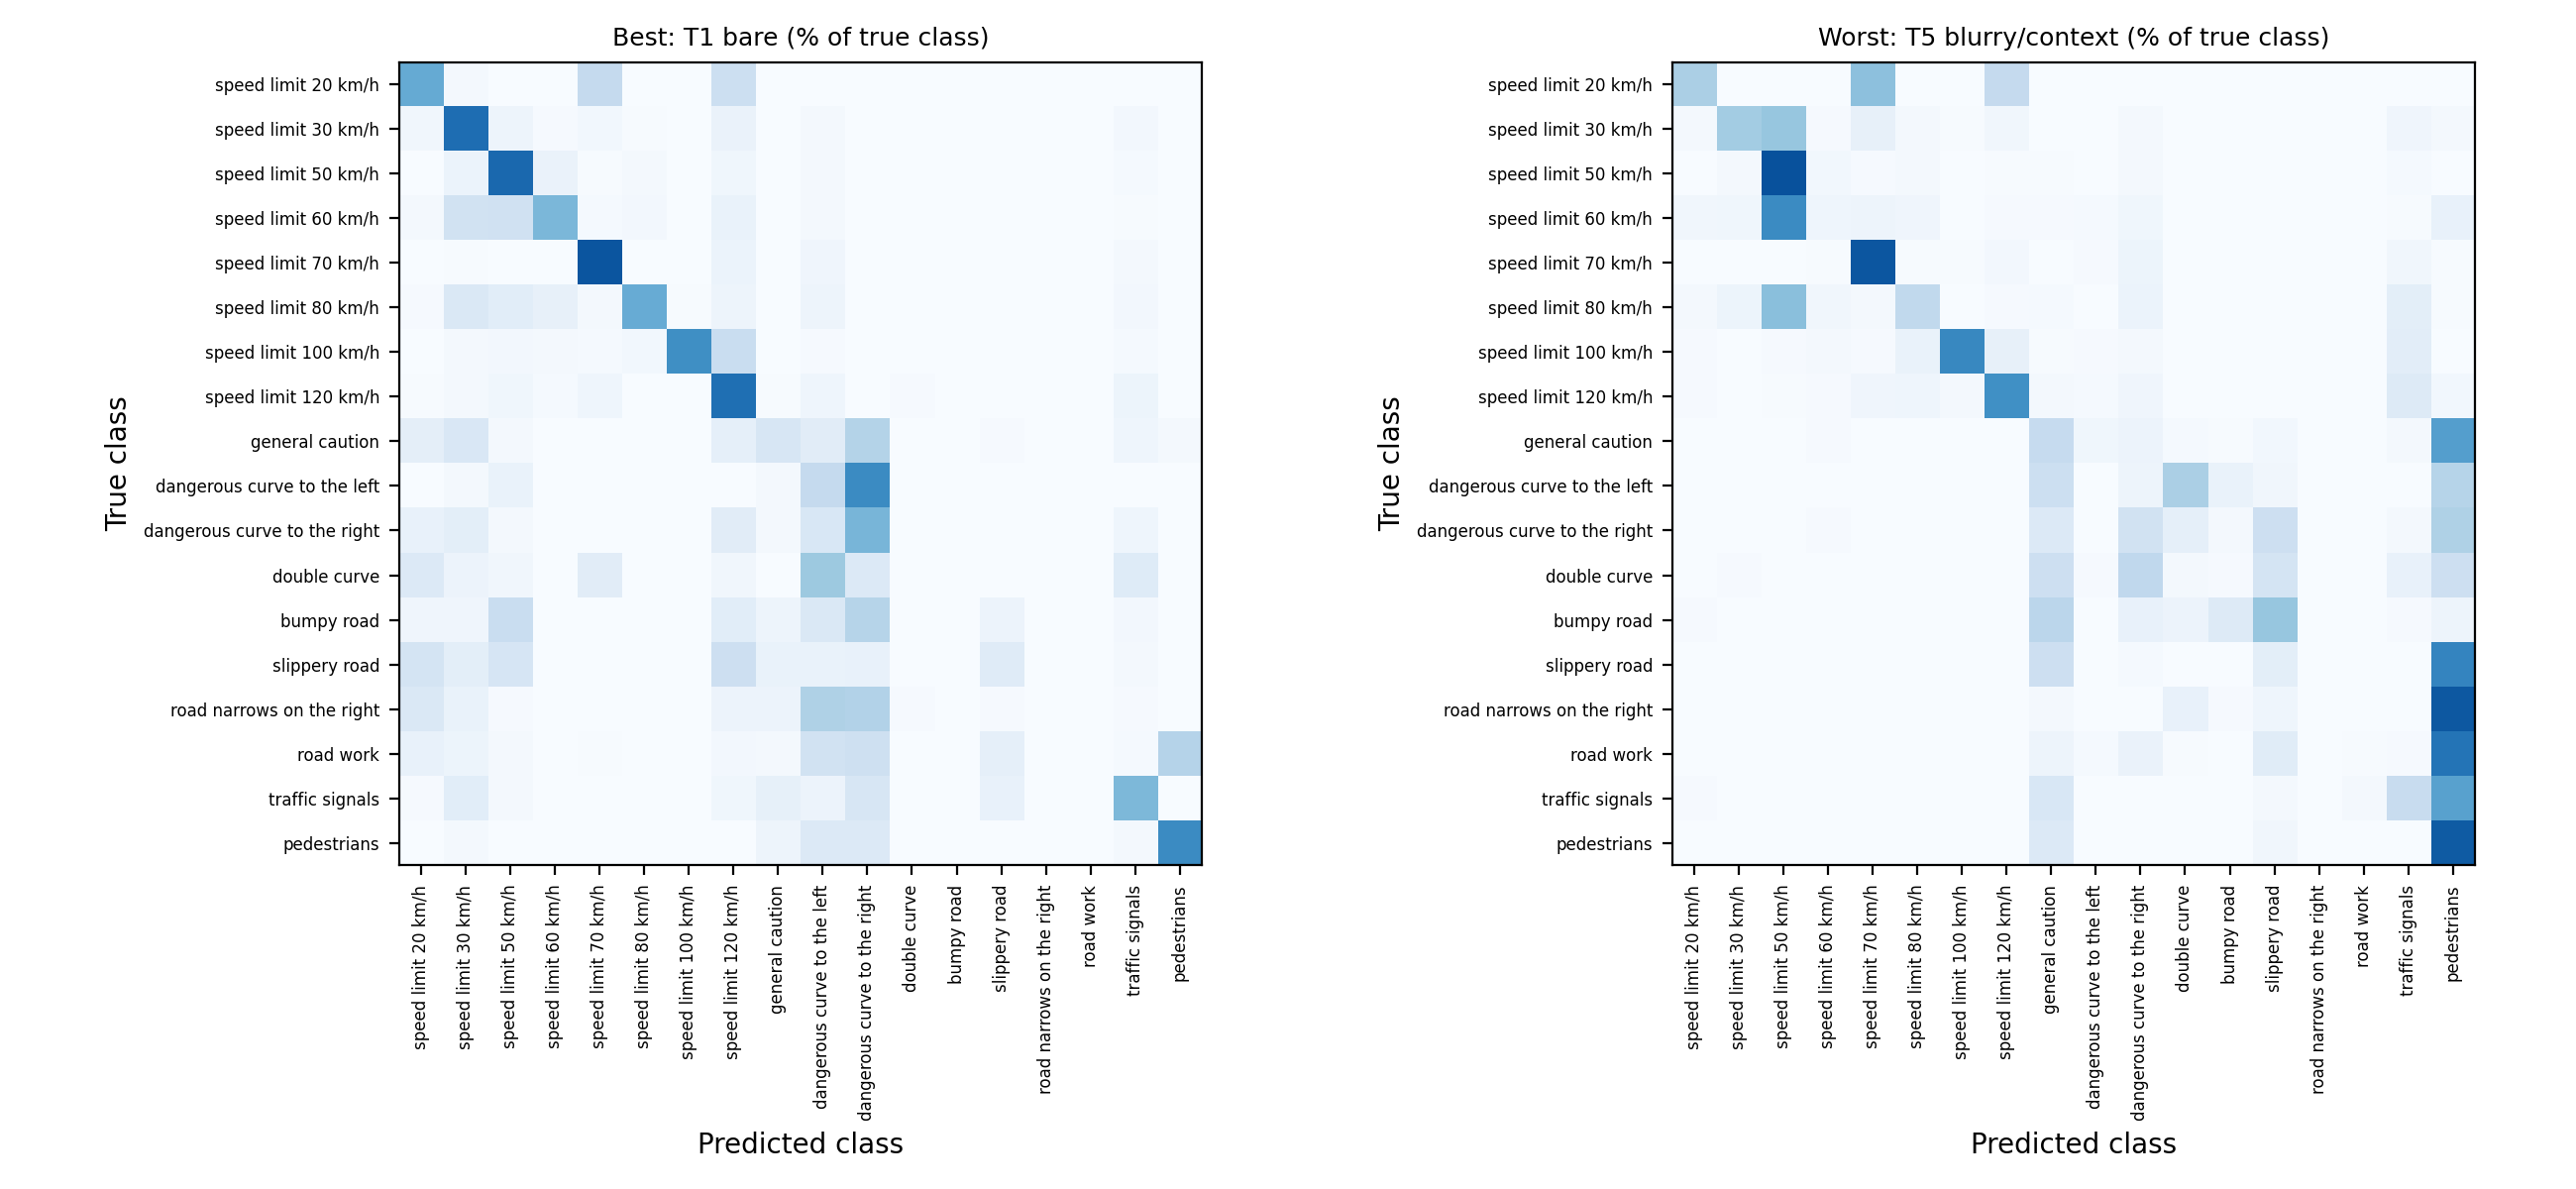

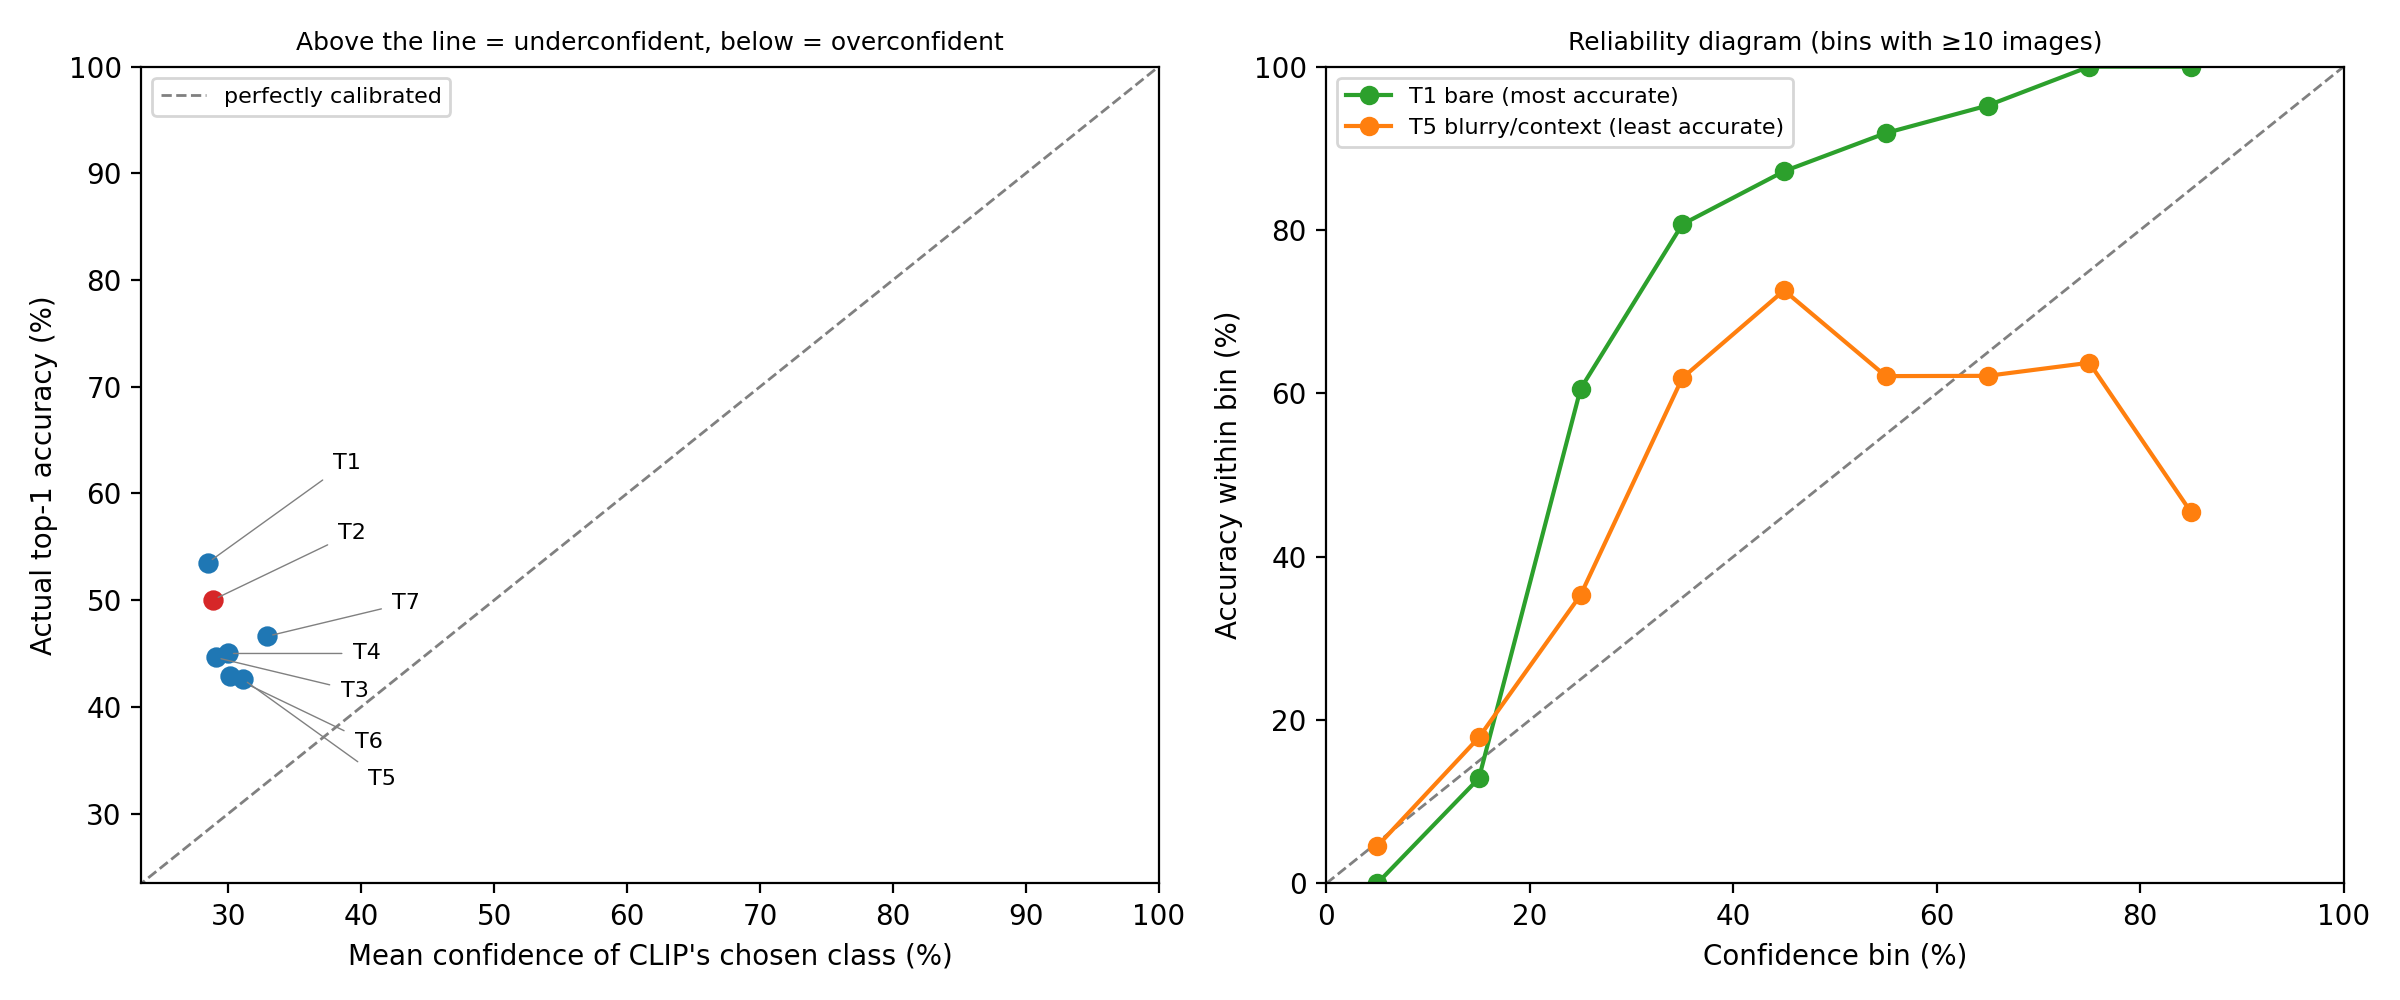

,template,prompt_example,top1,top1_ci_lo,top1_ci_hi,balanced_acc,delta_vs_baseline_pp,mcnemar_p_vs_baseline,mean_confidence,overconfidence_pp,ece,mean_conf_when_wrong
0,T1 bare,speed limit 30 km/h,0.5350,0.5226,0.5475,0.4101,3.4694,0.0000,0.2844,-25.0588,0.2635,0.1963
1,T2 photo (baseline),a photo of a speed limit 30 km/h,0.5003,0.4871,0.5126,0.3659,0.0000,NaN,0.2885,-21.1796,0.2367,0.2074
2,T3 domain,"a photo of a speed limit 30 km/h, a type of tr...",0.4463,0.4345,0.4592,0.3496,-5.4082,0.0000,0.2904,-15.5880,0.1603,0.2432
3,T4 functional,a road sign indicating speed limit 30 km/h,0.4500,0.4374,0.4629,0.3614,-5.0340,0.0000,0.2996,-15.0355,0.1678,0.2540
4,T5 blurry/context,a blurry photo of a speed limit 30 km/h sign o...,0.4260,0.4131,0.4388,0.3211,-7.4320,0.0000,0.3108,-11.5184,0.1372,0.2661
5,T6 verbose,"a photograph of a speed limit 30 km/h, showing...",0.4291,0.4160,0.4406,0.3185,-7.1259,0.0000,0.3009,-12.8179,0.1287,0.2516
6,T7 irrelevant,"a photo of a speed limit 30 km/h, taken on a s...",0.4662,0.4536,0.4787,0.3112,-3.4184,0.0000,0.3293,-13.6866,0.1599,0.2815
7,Ensemble of T1-T7,mean of T1-T7 embeddings,0.4828,0.4704,0.4961,0.3575,-1.7517,0.0001,0.3227,-16.0083,0.1626,0.2644


{
  "n_images": 5880,
  "n_classes": 18,
  "chance_acc": 0.05555555555555555,
  "majority_class_acc": 0.12755102040816327,
  "top1_mean": 0.46469873663751216,
  "top1_std": 0.03987516301708106,
  "top1_min": 0.4260204081632653,
  "top1_max": 0.5350340136054422,
  "top1_range_pp": 10.901360544217692,
  "best_template": "T1 bare",
  "worst_template": "T5 blurry/context",
  "balanced_range_pp": 9.89418775668775,
  "most_confident_template": "T7 irrelevant",
  "most_confident_template_top1": 0.466156462585034,
  "confidence_picks_best": false,
  "spearman_conf_vs_acc_across_templates": -0.6071428571428572,
  "logit_scale": 100.0,
  "top1_range_pp_ci": [
    9.88095238095238,
    12.057823129251705
  ]
}


In [3]:
from IPython.display import Image, display
import pandas as pd, json
for f in ['fig1_template_accuracy','fig2_per_class_heatmap','fig3_confusion_best_worst','fig4_confidence_vs_accuracy']:
    display(Image(f'results/{f}.png'))
display(pd.read_csv('results/template_accuracy.csv').round(4))
print(json.dumps(json.load(open('results/spread_summary.json')), indent=2))

In [4]:
# Download all results (skip the big feature cache)
!cd results && zip -q ../results.zip *.csv *.json *.png *.txt
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>